# Duplas y tríos por línea — Chaco For Ever

Para cada jugador / dupla / trío, cuánto tiempo jugaron **juntos** y cómo le fue al
equipo en esos minutos: **xG a favor − xG en contra por 90**, contra el resto de los
minutos ("con y sin").

Líneas que se analizan: **zaga central**, **banda derecha** (lateral + extremo),
**banda izquierda**, **mediocampo** (volantes centrales) y **ataque** (dupla de
delanteros + trío con un extremo).

> Es un análisis de **características del equipo de HOY**: los jugadores de
> `config.JUGADORES_FUERA` (los que ya no están en el club) **no** entran. Para lo que
> aportaron durante la temporada, ver `analisis_temporada.ipynb`.

Los tramos salen de los minutos de entrada/salida (`lineups_clean.csv`), el xG del
`shotmap_clean.csv` con su minuto, y las rojas del `incidents_clean.csv`.

Números por combinación:
- `xgdiff_p90_con` — crudo, todos los minutos con la combinación en cancha.
- `xgdiff_p90_sin_mp` — el resto de los minutos **de los mismos partidos** (saca el
  sesgo de calendario).
- `delta_xgdiff` = con − sin (mismos partidos). **El número que importa.**
- `xgdiff_p90_11v11` — solo tramos con 11 contra 11.

Es un **embudo para mirar**, no un ranking cerrado.


In [1]:
import os, sys

%load_ext autoreload
%autoreload 2

if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import config
from src.analysis.season import load_matches
from src.scraping.chaco_scraper import _match_done
from src.analysis.lineups import (
    chaco_players_by_role, chaco_units, unit_report, combo_impact,
    CENTRAL_MID_ROLES, WIDE_MID_ROLES, DEF_ROLES, ATTACK_ROLES,
)
from src.visualization.lineups import (
    plot_units_summary, plot_combo_ranking, plot_combo_scatter, plot_pair_matrix,
)
from IPython.display import Image, display

def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

# ============================================================
# CONFIGURAR ACA
SEASON      = '2026'
MIN_MINUTOS = 200    # piso de minutos de temporada para entrar al pool de una linea
MIN_JUNTOS  = 160    # piso de minutos juntos para que una combinacion aparezca
# ============================================================

BASE_DIR  = config.season_data_dir(SEASON)
PLOTS_DIR = os.path.join(config.season_plots_dir(SEASON), 'mediocampo')
os.makedirs(PLOTS_DIR, exist_ok=True)

MATCH_KEYS = [mk for mk in load_matches(SEASON)
              if _match_done(os.path.join(BASE_DIR, mk))]

COLS = ['combo', 'partidos_juntos', 'minutos_juntos',
        'xgf_p90_con', 'xga_p90_con', 'xgdiff_p90_con',
        'xgdiff_p90_sin_mp', 'delta_xgdiff', 'xgdiff_p90_11v11']

print(f'Temporada {SEASON} - {len(MATCH_KEYS)} partidos con datos')
if config.JUGADORES_FUERA:
    print(f'Fuera del analisis (JUGADORES_FUERA): {", ".join(config.JUGADORES_FUERA)}')

# UNITS excluye a config.JUGADORES_FUERA por default (analisis del equipo de hoy)
UNITS = chaco_units(SEASON, base_dir=BASE_DIR, min_minutes=MIN_MINUTOS)
for name, u in UNITS.items():
    print(f"  {name:12s} ({u['size']}): {', '.join(u['players'])}")


Temporada 2026 - 31 partidos con datos
Fuera del analisis (JUGADORES_FUERA): R. Zules, L. Marinucci, I. Enriquez, M. Noble
  banda_der    (2): A. Alonso, A. Luque, E. Gaggi, J. C. Cerrudo
  banda_izq    (2): A. Ojeda, G. Melgarejo, L. Fernandez, L. Pruzzo
  zaga         (2): D. Valdez, R. Garay, M. Silvera, L. Mihovilcevich
  medio        (2): B. Nievas, J. Carrizo, A. Lioi, S. Valenzuela, G. Ramirez, B. B. García, B. Guerra
  ataque       (2): G. Pacheco, M. S. Romero, M. D. Chaves
  ataque_trio  (3): A. Alonso, E. Gaggi, G. Melgarejo, G. Pacheco, J. C. Cerrudo, L. Fernandez, M. D. Chaves, M. S. Romero


## 1. La mejor combinación de cada línea

Por línea, la combinación con mejor xGdiff/90: cuánto es de ellos (punto lleno) vs
el resto de esos mismos partidos (círculo vacío).


=== BANDA_DER ===
                   combo  partidos_juntos  minutos_juntos  xgf_p90_con  xga_p90_con  xgdiff_p90_con  xgdiff_p90_sin_mp  delta_xgdiff  xgdiff_p90_11v11
     A. Luque + E. Gaggi               13           861.0        1.100        0.607           0.493              0.332         0.161             0.497
A. Luque + J. C. Cerrudo               12           621.0        0.658        0.736          -0.078              0.098        -0.175            -0.031

=== BANDA_IZQ ===
                   combo  partidos_juntos  minutos_juntos  xgf_p90_con  xga_p90_con  xgdiff_p90_con  xgdiff_p90_sin_mp  delta_xgdiff  xgdiff_p90_11v11
 A. Ojeda + L. Fernandez               12           858.0        1.113        0.674           0.439              0.316         0.123             0.375
 A. Ojeda + G. Melgarejo                8           194.0        1.015        0.983           0.032              0.435        -0.403             0.032
G. Melgarejo + L. Pruzzo                8           240.

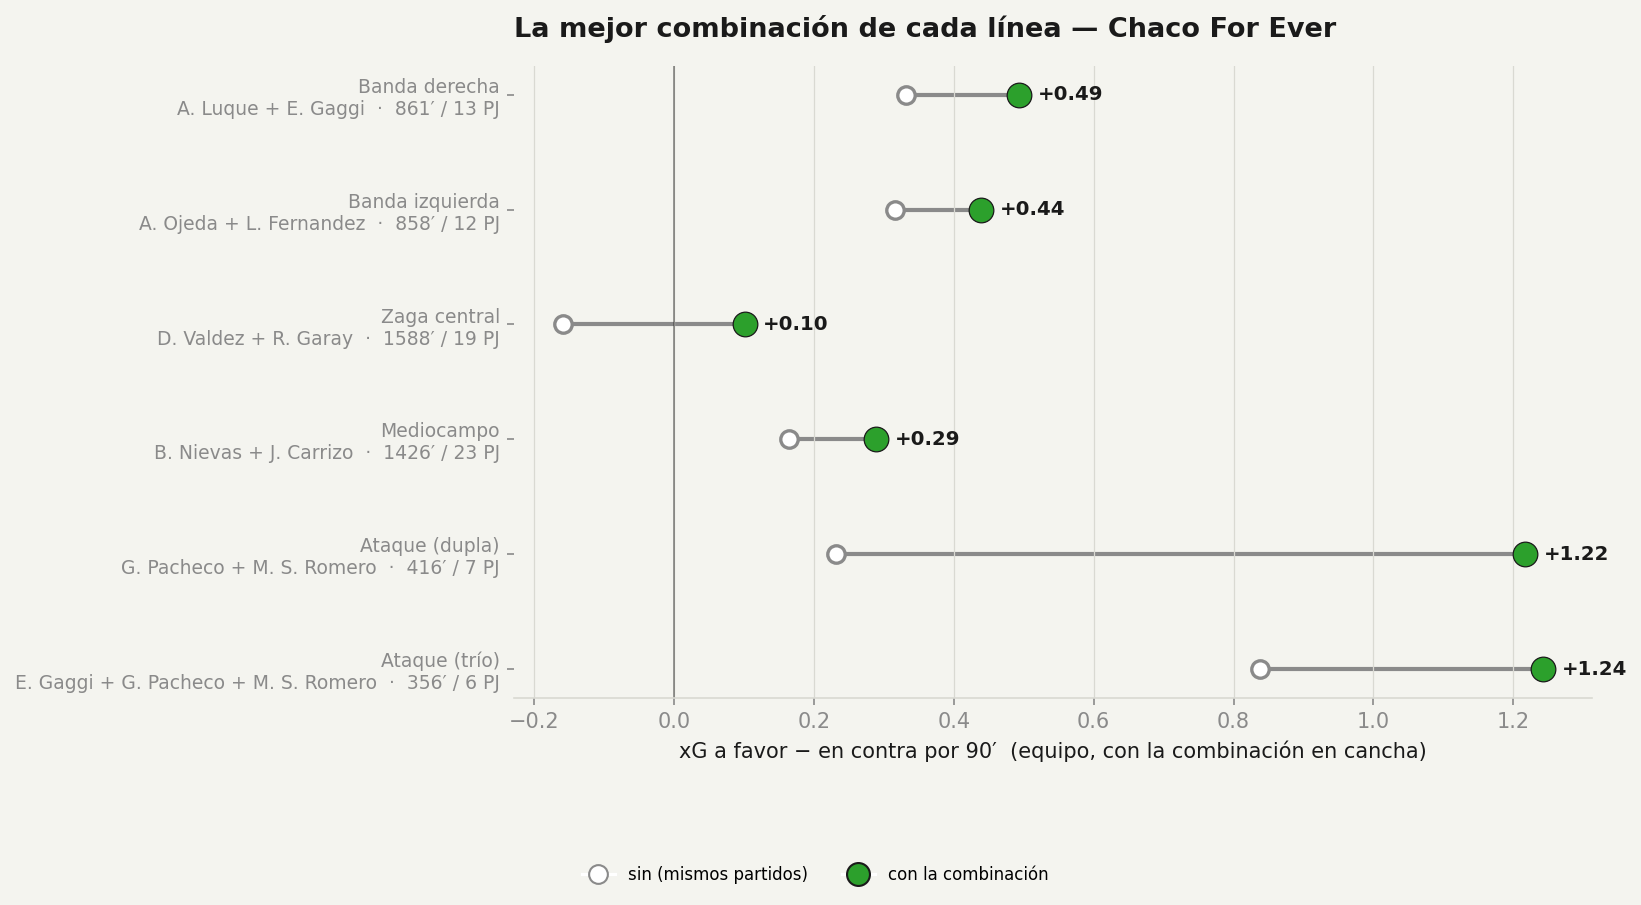

In [2]:
REPORT = unit_report(MATCH_KEYS, BASE_DIR, SEASON, min_together=MIN_JUNTOS)

for name, df in REPORT.items():
    print(f'\n=== {name.upper()} ===')
    print(df[COLS].head(6).to_string(index=False) if not df.empty
          else '(sin combinaciones con minutos suficientes)')

plot_units_summary(REPORT, save_path=os.path.join(PLOTS_DIR, 'lineas_resumen.png'))
show(os.path.join(PLOTS_DIR, 'lineas_resumen.png'))

## 2. Cada línea en detalle

Ranking (dumbbell con/sin) de cada línea.

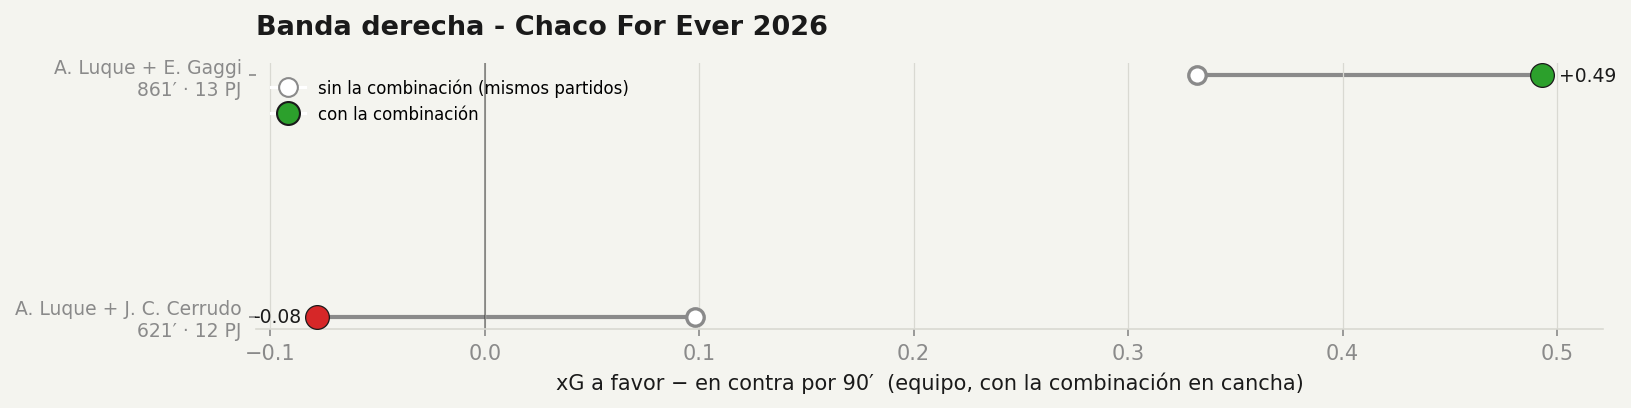

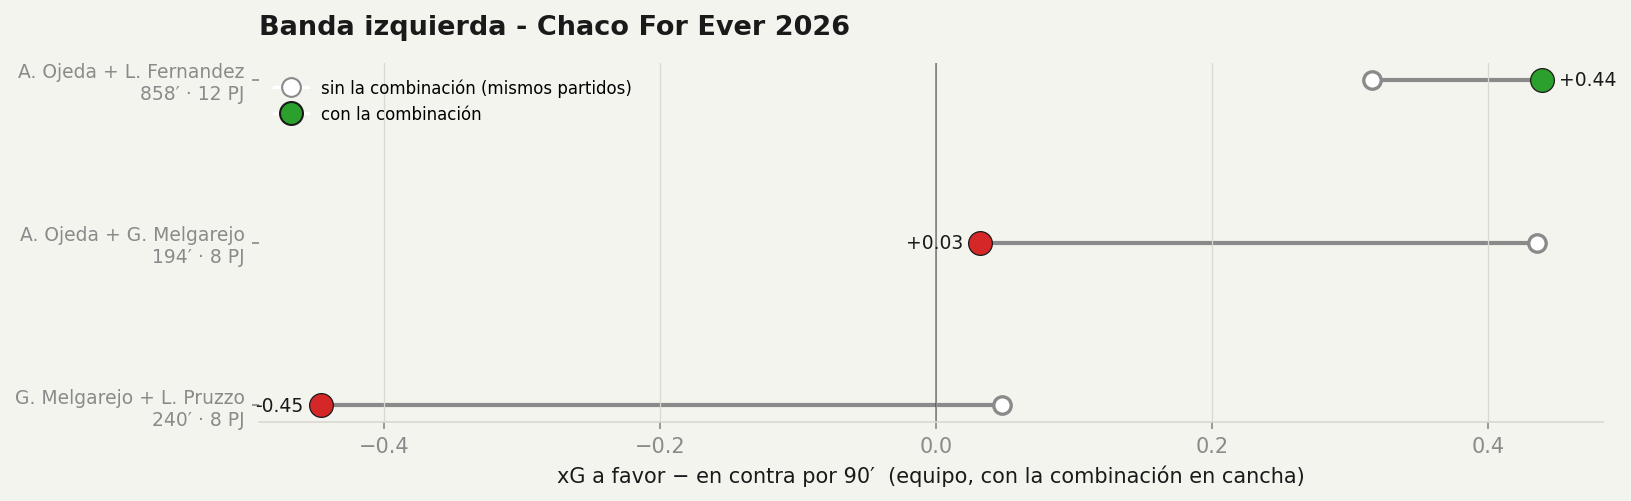

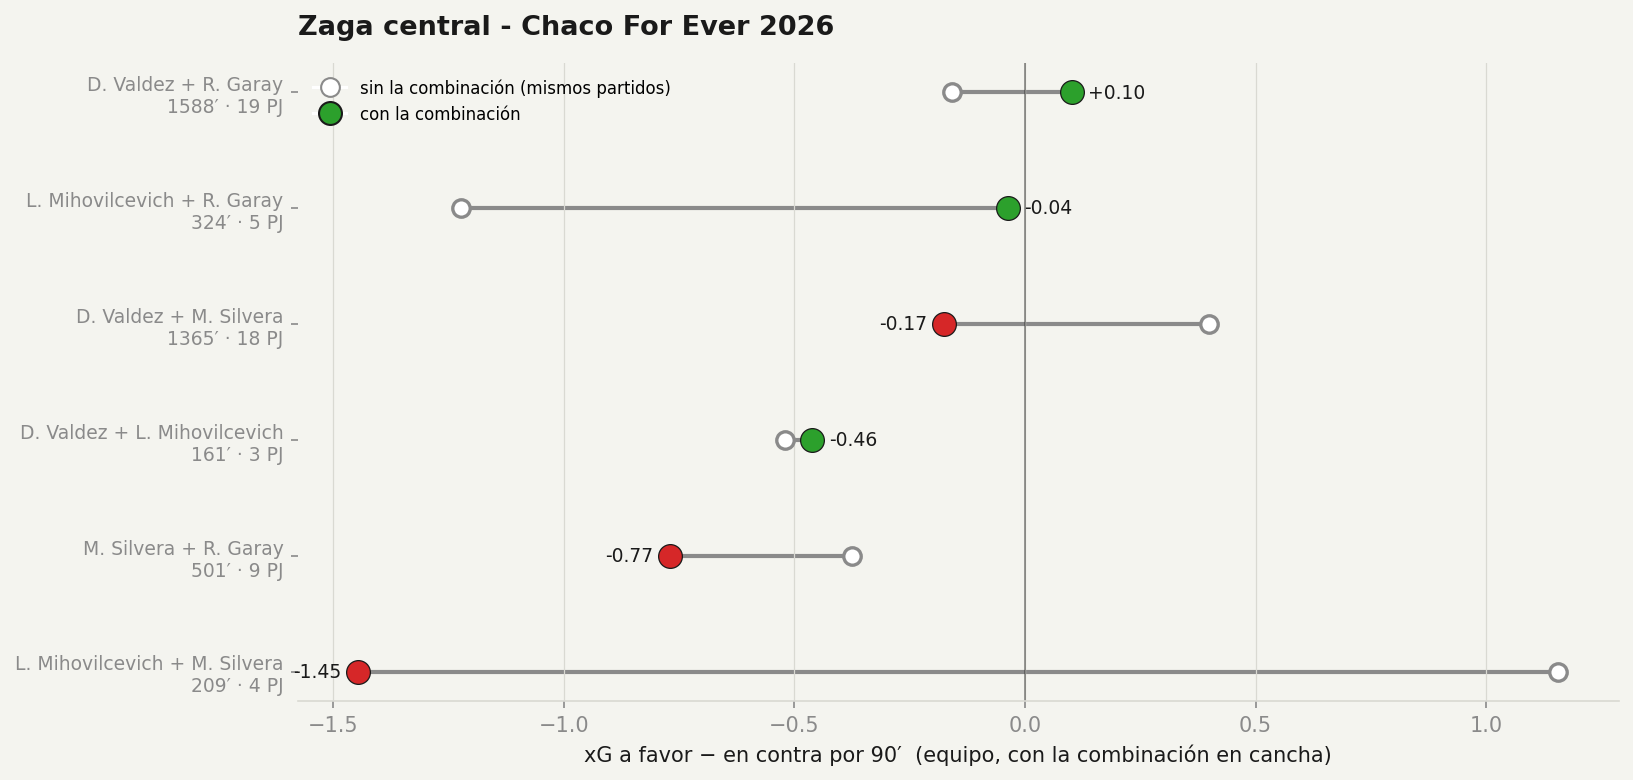

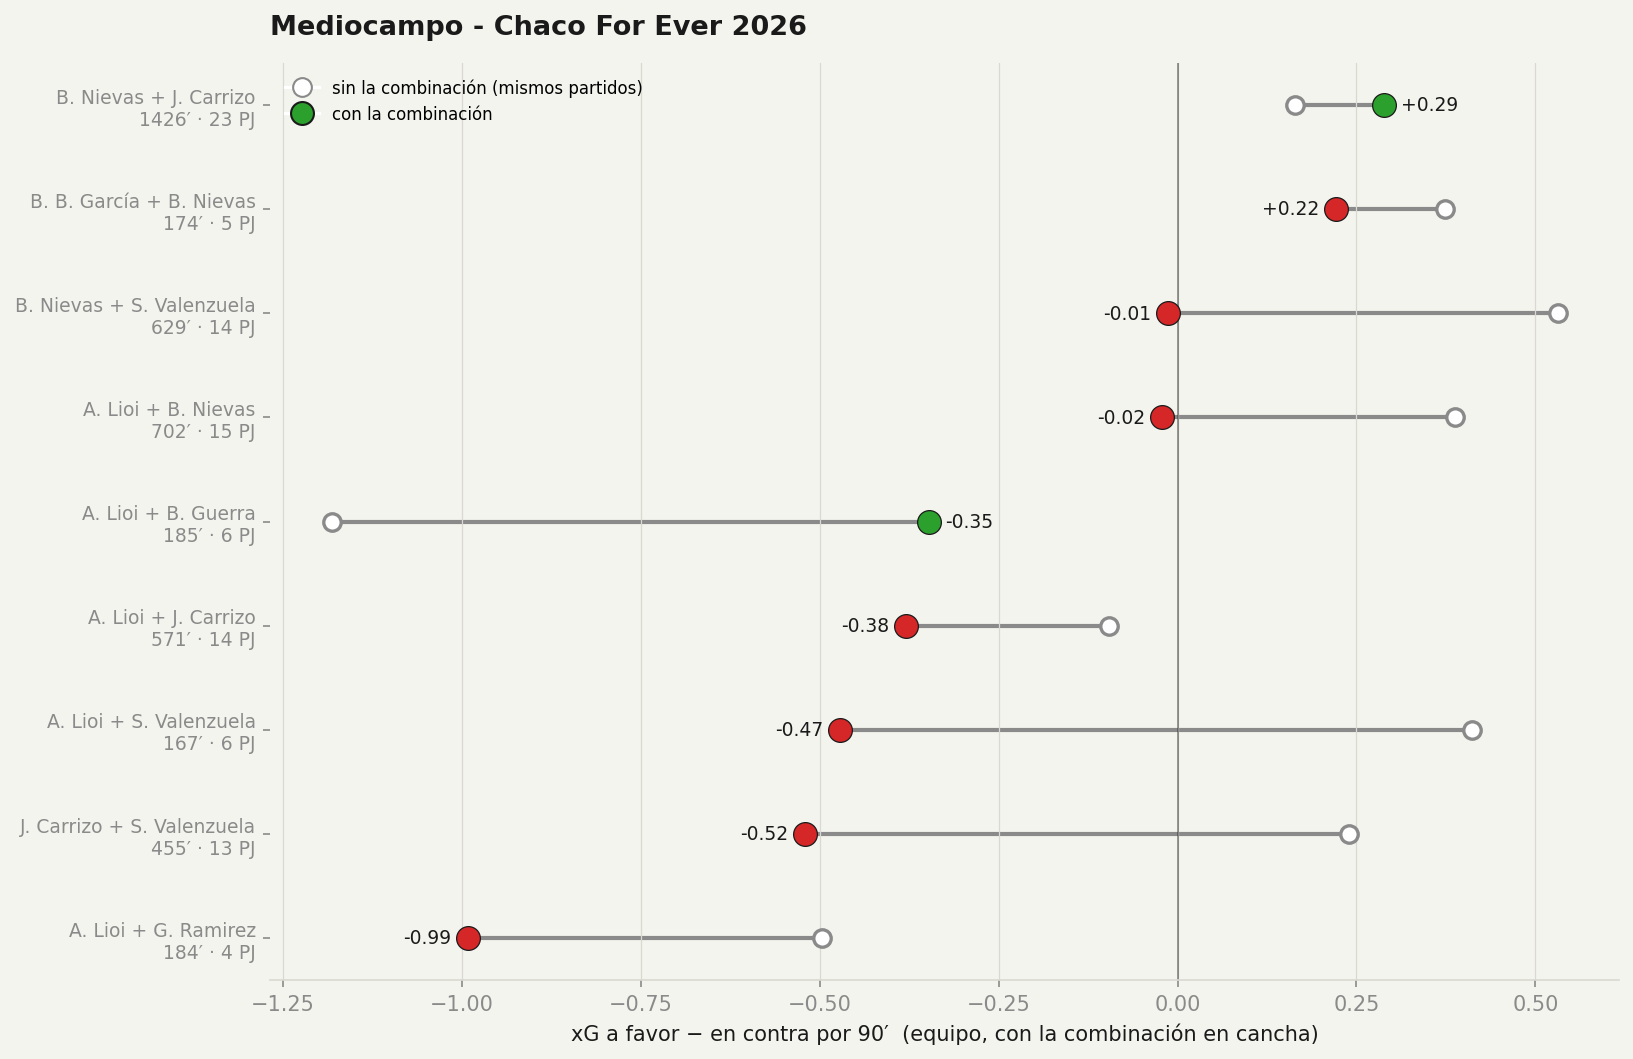

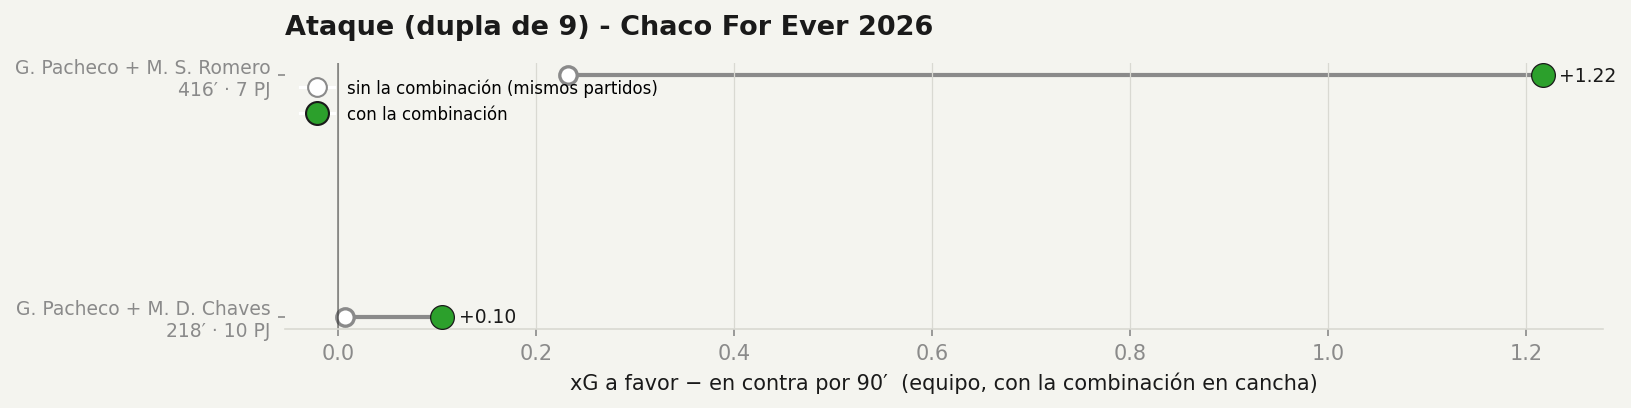

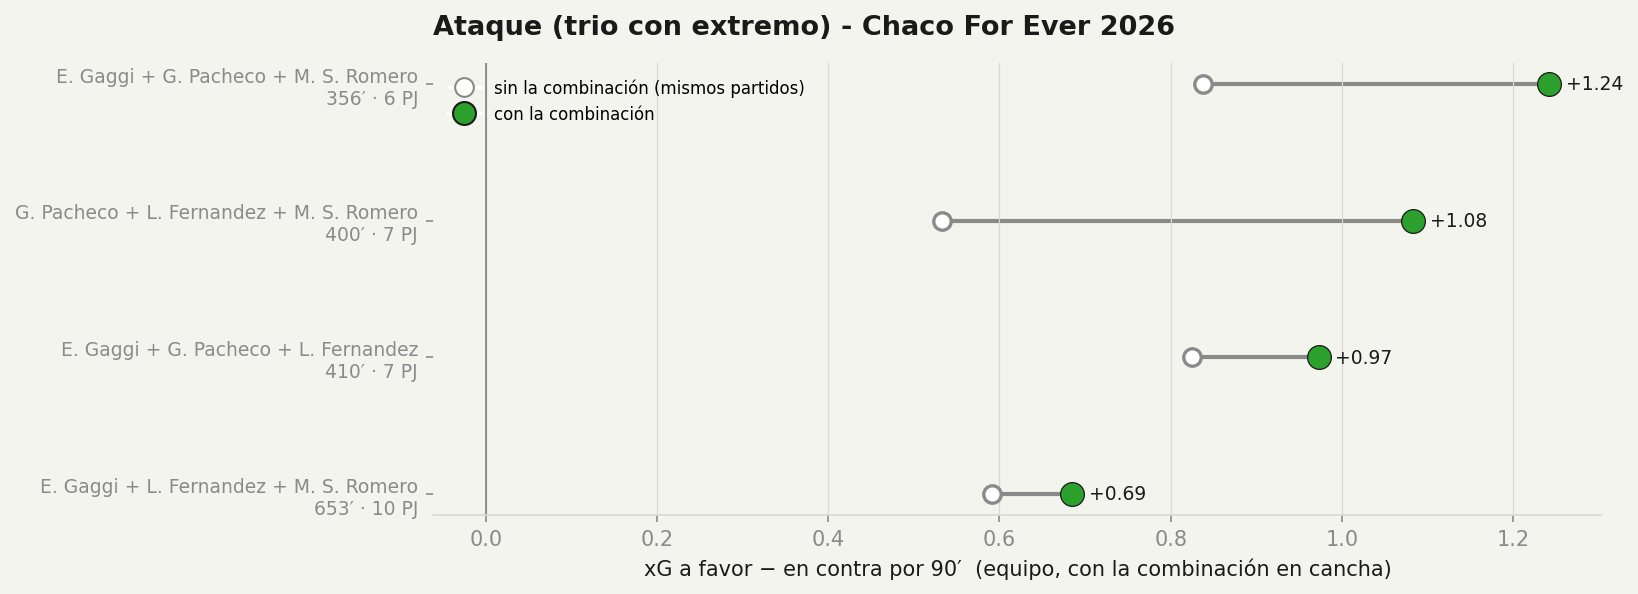

In [3]:
TITULOS = {'zaga': 'Zaga central', 'banda_der': 'Banda derecha',
           'banda_izq': 'Banda izquierda', 'medio': 'Mediocampo',
           'ataque': 'Ataque (dupla de 9)', 'ataque_trio': 'Ataque (trio con extremo)'}

for name, df in REPORT.items():
    if df.empty:
        continue
    p = os.path.join(PLOTS_DIR, f'{name}_ranking.png')
    plot_combo_ranking(df, top=10,
                       title=f"{TITULOS.get(name, name)} - Chaco For Ever {SEASON}",
                       save_path=p)
    show(p)

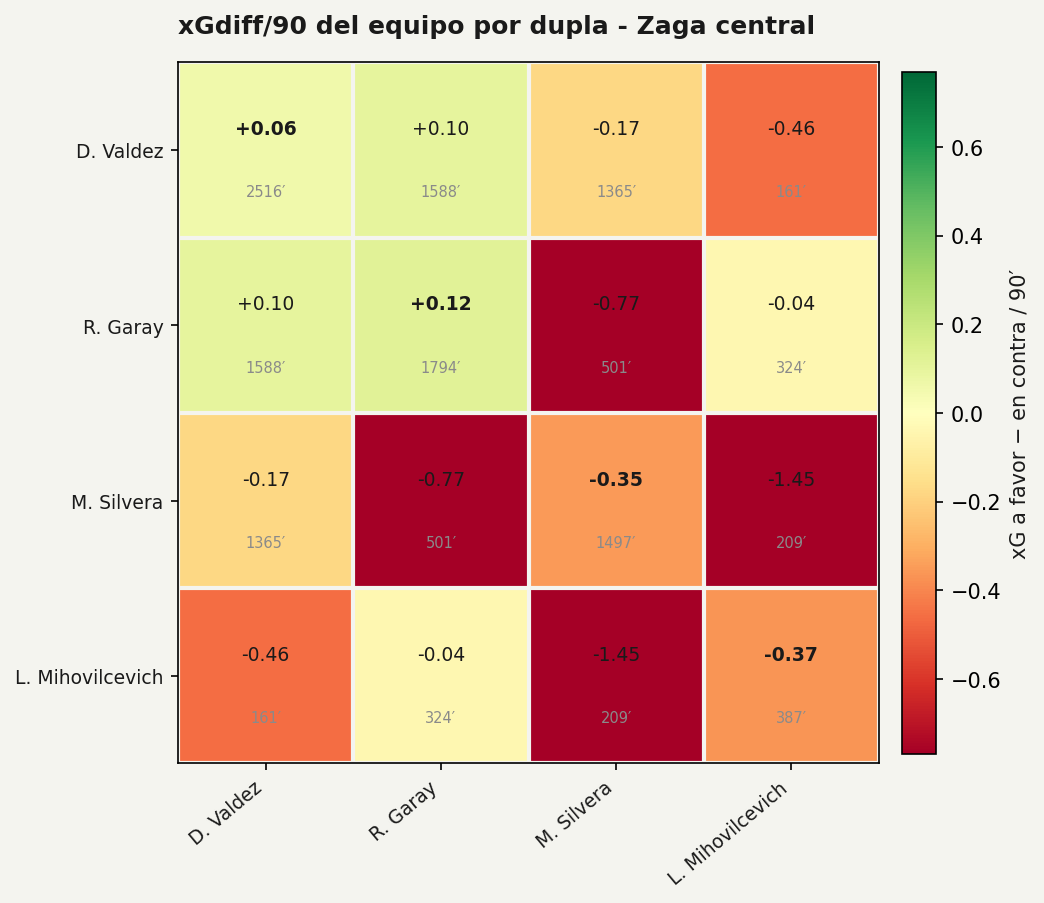

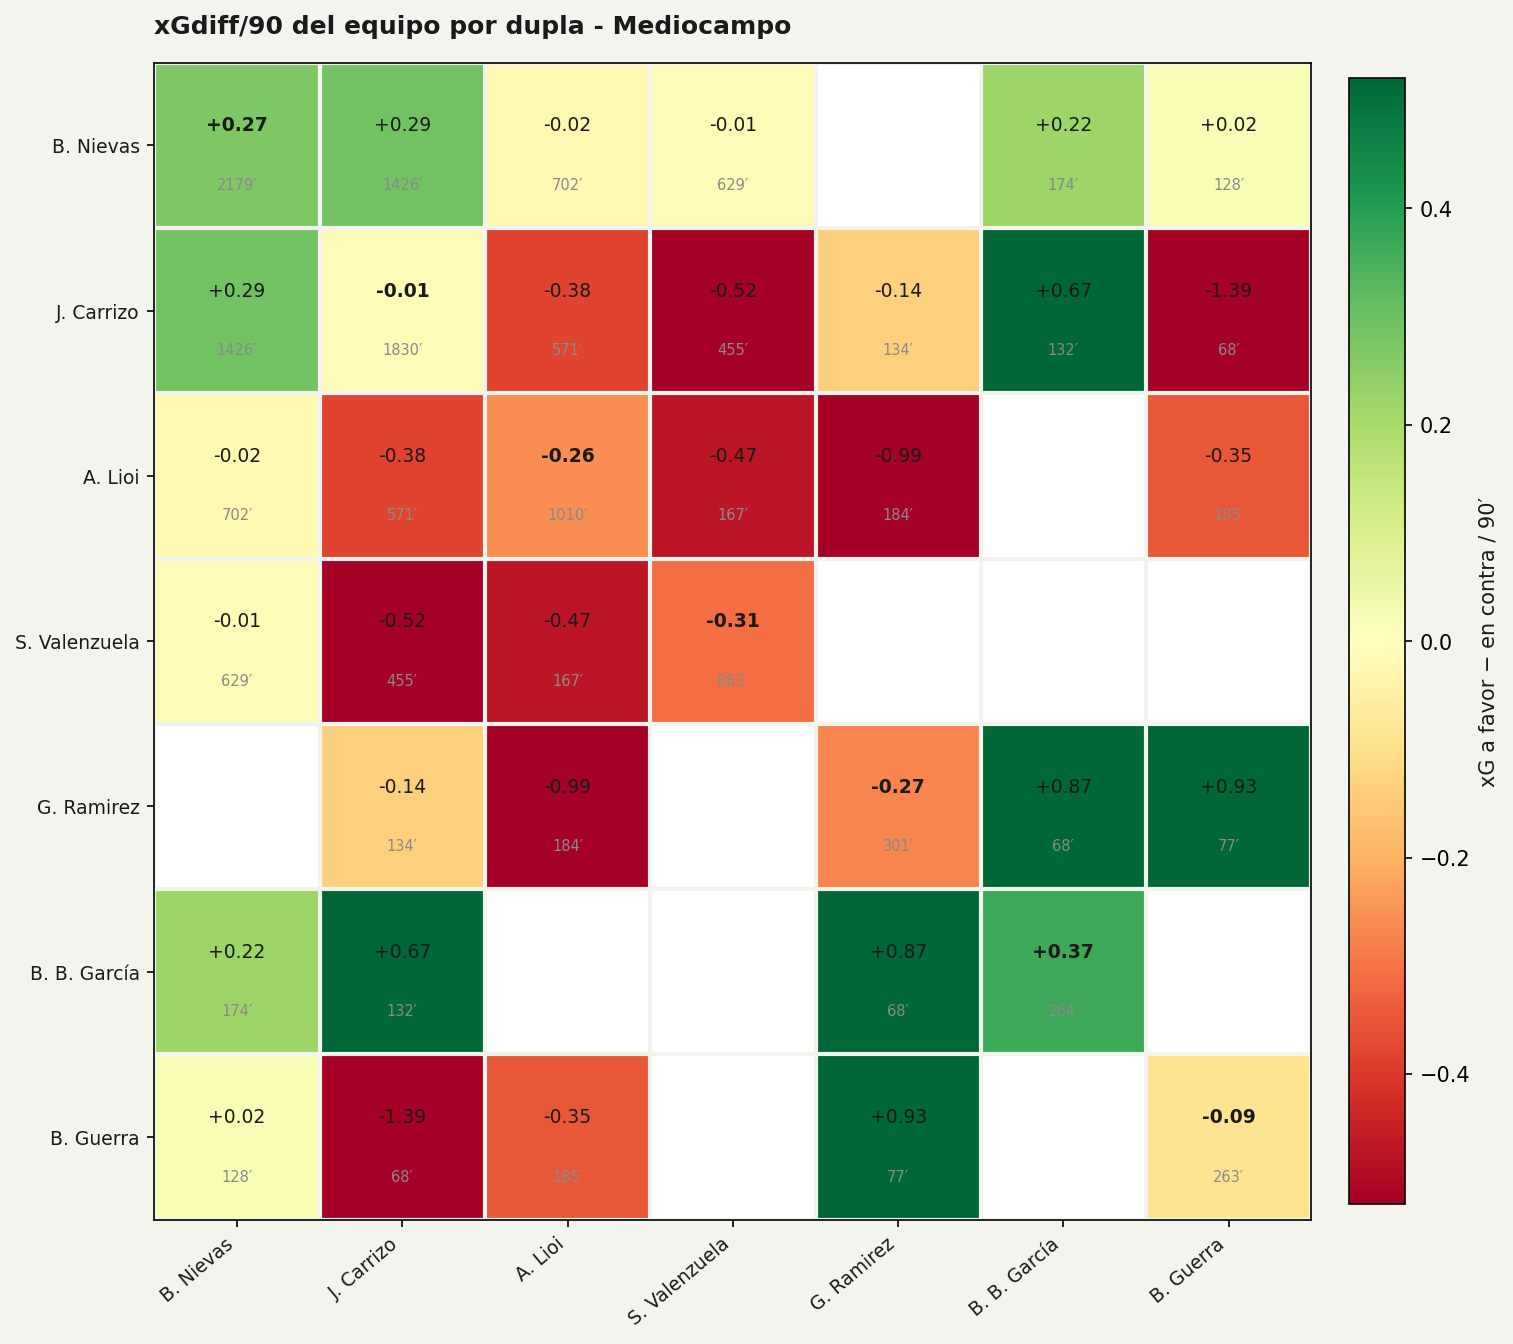

In [4]:
# Matriz jugador x jugador donde hay varios candidatos: zaga central y mediocampo
for name, roles, mm in [('zaga', DEF_ROLES, 200), ('medio', CENTRAL_MID_ROLES, 250)]:
    players = chaco_players_by_role(SEASON, roles, min_minutes=mm, base_dir=BASE_DIR)
    solo  = combo_impact(MATCH_KEYS, BASE_DIR, players, size=1, min_minutes_together=1)
    pares = combo_impact(MATCH_KEYS, BASE_DIR, players, size=2, min_minutes_together=60)
    p = os.path.join(PLOTS_DIR, f'matriz_{name}.png')
    plot_pair_matrix(pares, solo, players=players,
                     title=f'xGdiff/90 del equipo por dupla - {TITULOS[name]}',
                     save_path=p)
    show(p)

## 3. Cuánto juega cada combinación vs cuánto rinde

Todas las líneas juntas: eje x = minutos juntos, eje y = xGdiff/90 con la combinación.
Arriba-derecha = juega mucho y rinde.

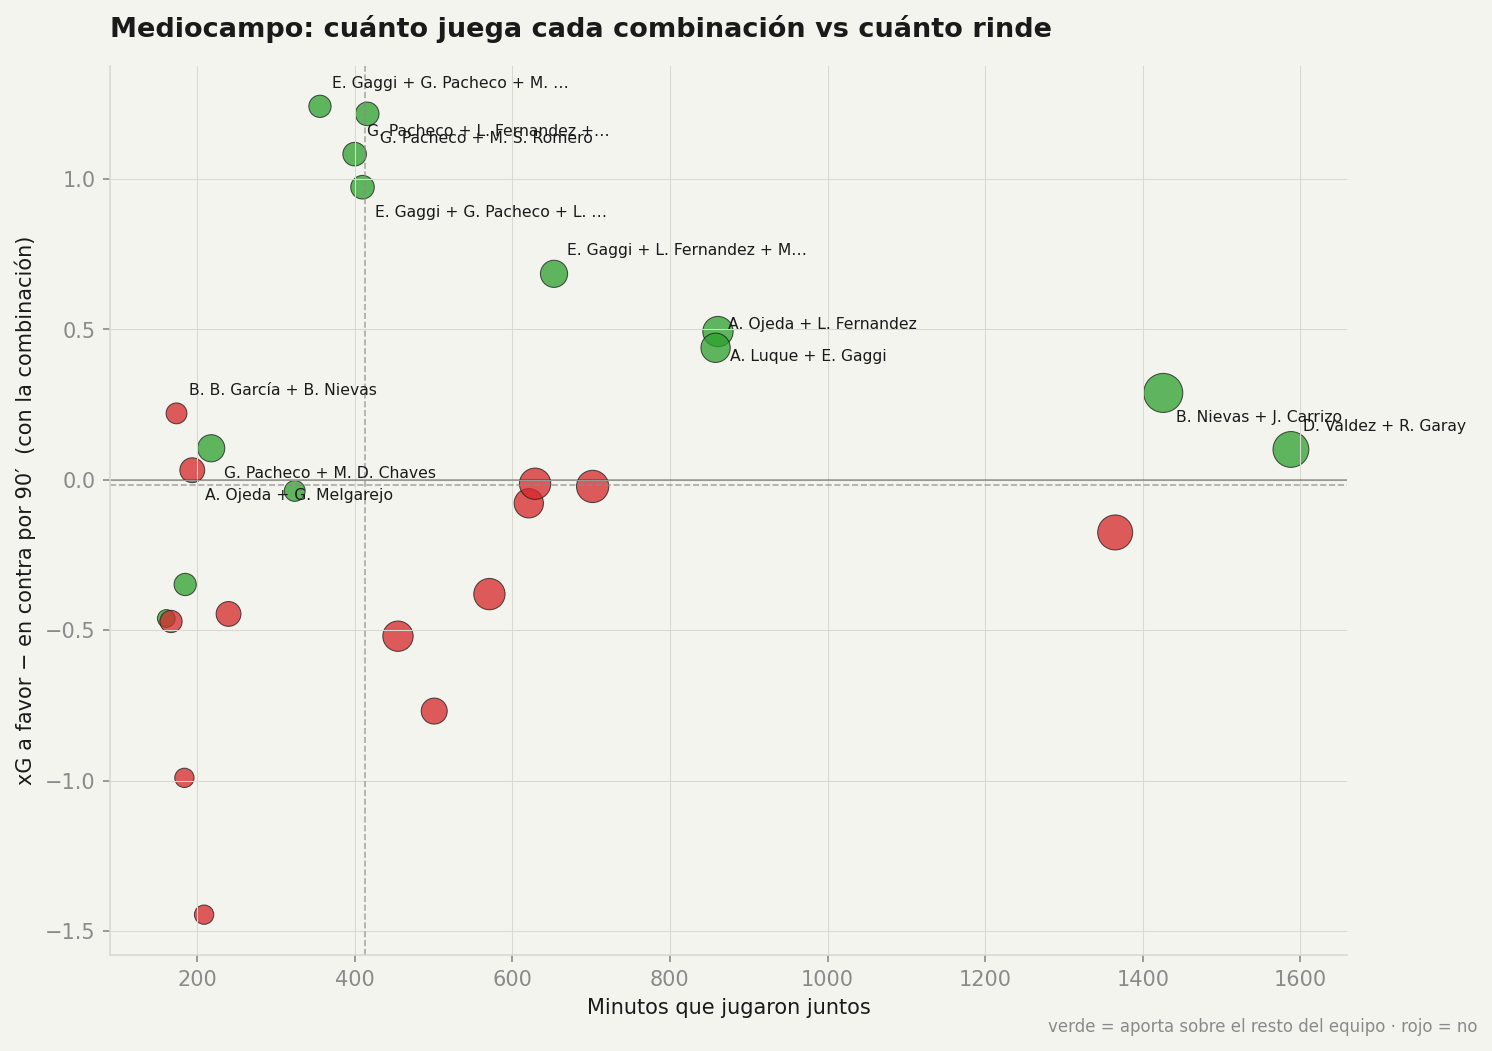

In [5]:
todo = pd.concat([df.assign(linea=n) for n, df in REPORT.items() if not df.empty],
                 ignore_index=True)
plot_combo_scatter(todo, save_path=os.path.join(PLOTS_DIR, 'combos_scatter.png'))
show(os.path.join(PLOTS_DIR, 'combos_scatter.png'))

## 4. Una combinación, partido a partido

In [6]:
# Cambia LINEA por la que quieras mirar (zaga, banda_der, banda_izq, medio, ataque, ataque_trio)
LINEA = 'ataque_trio'
df = REPORT[LINEA]
COMBO = (df.iloc[0]['jugadores'] if not df.empty
         else tuple(UNITS[LINEA]['players'][:UNITS[LINEA]['size']]))

_, detalle = combo_impact(MATCH_KEYS, BASE_DIR, list(COMBO), size=len(COMBO),
                          min_minutes_together=1, return_per_match=True)
print('Combinacion:', ' + '.join(COMBO))
print(detalle.to_string(index=False))

Combinacion: E. Gaggi + G. Pacheco + M. S. Romero
                               combo                                mk  minutos  xgf  xga  gf  ga  local
E. Gaggi + G. Pacheco + M. S. Romero         2026-07-11_vs_san_telmo_a     52.0 1.01 0.47   2   1  False
E. Gaggi + G. Pacheco + M. S. Romero   2026-08-02_vs_deportivo_moron_h     62.0 2.58 0.04   1   0   True
E. Gaggi + G. Pacheco + M. S. Romero 2026-08-16_vs_gimnasia_de_jujuy_a     58.0 0.00 0.00   0   0  False
E. Gaggi + G. Pacheco + M. S. Romero         2026-08-22_vs_los_andes_h     71.0 0.84 0.38   1   0   True
E. Gaggi + G. Pacheco + M. S. Romero        2026-08-26_vs_san_miguel_h     55.0 1.14 0.18   0   0   True
E. Gaggi + G. Pacheco + M. S. Romero   2026-09-20_vs_almirante_brown_h     58.0 0.53 0.12   1   0   True


## Cómo leer esto — límites

- **28 partidos, muestra chica.** Las duplas de titulares tienen mucho minuto; las
  que llevan suplentes, poco. Un `xgdiff_p90` sobre ~200′ es orientativo.
- **Colinealidad.** Los titulares juegan casi siempre juntos, así que su "sin" es
  muestra chica. Mirar `minutos_sin`.
- **Sesgo de calendario.** Chaco rinde mejor en la segunda vuelta. Los que llegaron o
  entraron a mitad de año (Gaggi, Fernández) arrastran esa mejora del equipo entero.
  Por eso el número que importa es `delta_xgdiff` (con − sin, **mismos partidos**).
- **Rojas.** En los tramos con expulsados el equipo con más hombres genera más xG;
  `xgdiff_p90_11v11` deja solo el 11 contra 11.
- **Endogeneidad.** Al que rinde, el DT lo hace jugar más. Correlación ≠ causa.
- El xG de SofaScore falta en algunos partidos (`audit.print_audit`): esos minutos
  cuentan para el denominador pero aportan 0 de xG. Son pocos.
- El rol (quién es "lateral", "extremo", etc.) sale del pool de scouting
  (`pool_scouting.csv`, posición media en cancha). Si está viejo, refrescalo.